# Steam game recommendations: implicit-feedback ALS against course methods

**Our outside-the-course method** is matrix factorisation for implicit feedback (Hu, Koren & Volinsky, 2008), fitted with alternating least squares (ALS). Every user and game gets a vector of hidden factors, and their dot product scores how likely the user is to play the game. Playtime is not treated as a rating but as *confidence*: a played game is a positive with confidence $c = 1 + \alpha \log(1 + \text{minutes})$, an unplayed game is a weak negative with confidence 1. ALS alternately solves for all user vectors with the game vectors fixed and the other way round; each half-step is a set of small least-squares problems, implemented from scratch in `recommender/als.py` (NumPy + Numba).

**Course methods** it is compared with: association rules from frequent itemsets (PCY for pairs, Apriori for triples; `recommender/itemsets.py`, `recommender/rules.py`), item-item similarity (cosine or Jaccard), and popularity. Clustering (spherical k-means with the Davies–Bouldin index) is used to describe the learned game vectors and to diversify the recommendation lists.

Outline:
1. Data: played games, one shared filter, train / validation / test split.
2. Tuning: every method is tuned on validation with the same rule.
3. Convergence of ALS.
4. Test results over five random splits, with bootstrap intervals.
5. Cross-check of our ALS against the `implicit` library.
6. What ALS learned: similar games, and clusters of game vectors compared with Steam tags.
7. Diversifying the lists by cluster.

**How to run.** From the repository root: `pip install -r requirements-recommender.txt`, then run all cells. The slow parts (tuning grids, test runs over five splits, convergence traces) are cached as CSV files in `results/`, so a re-run takes about 15 minutes; delete a file there to recompute that part (all of them: several hours on a 12-core laptop). The unit tests run with `pytest`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from recommender import als, clusters, data, evaluate, itemsets
from recommender import experiments as ex

FIGURES = Path(data.DATA_DIR).parent / "figures"
FIGURES.mkdir(exist_ok=True)
N_SEEDS = 5                    # random splits for the test results
CONVERGENCE_SEEDS = 3
CONVERGENCE_SWEEPS = 30
CLUSTER_KS = [10, 20, 40]      # numbers of clusters for diversification
CAPS = [1, 2, 3, 4, 5, 10]     # at most this many games per cluster in a top-10 list (10 = no cap)
CHECK_FACTORS = 128            # size of the cross-check against implicit (any size tests the code)

## 1. Data

All methods share one data definition (`recommender/data.py`). The raw inventories repeat some users; duplicate (user, game) rows keep the largest playtime. A game counts for a user only if it was **played**: owned-but-unplayed games are left out, because bundles and giveaways make ownership weak evidence of taste, and every method is trained and scored on plays. Games need at least 50 players and users at least 5 played games; removing games can push users below 5 and the other way round, so the two filters repeat until both hold.

In [2]:
raw = data.read_user_items()
user_items = data.deduplicate(raw)
print(f"{len(raw):,} raw user-game rows, {len(raw) - len(user_items):,} duplicates removed, "
      f"{(user_items['playtime'] > 0).sum():,} played")

inter = data.build_interactions(user_items)
n_users, n_games = inter.playtime.shape
display(inter.filter_log)
print(f"{n_users:,} users x {n_games:,} games: {inter.playtime.nnz / (n_users * n_games):.2%} of the matrix is played")

5,153,209 raw user-game rows, 59,127 duplicates removed, 3,246,352 played


,users,games,played pairs
step,,,
played entries,68403,10050,3246352
filter pass 1,59717,3720,3146315
filter pass 2,59716,3718,3146213
filter pass 3,59716,3718,3146213


59,716 users x 3,718 games: 1.42% of the matrix is played


For every user, 20% of their played games are hidden as the **test** set; of the rest, another 20% are hidden as the **validation** set used for all tuning. The filter runs before the split, so it defines the population we evaluate: active users and games with at least 50 players. Recommending niche games is therefore not measured.

In [3]:
train_full, test = data.split_per_user(inter.playtime, test_frac=0.2, seed=0)
train, valid = data.split_per_user(train_full, test_frac=0.2, seed=1)
print(f"train {train.nnz:,}  validation {valid.nnz:,}  test {test.nnz:,} played pairs")

players = data.players_per_game(train)
print("training players per game: min {}, quartiles {}".format(players.min(), np.percentile(players, [25, 50, 75])))

train 2,013,843  validation 503,425  test 628,945 played pairs
training players per game: min 20, quartiles [ 58.   128.5  397.75]


## 2. Tuning every method with the same rule

Each method gets a grid of settings, scored on the validation games by NDCG@10. The same rule picks the setting for every method:

- **One-standard-error rule:** take the simplest setting whose NDCG is within one standard error (over users) of the best. "Simpler" is fixed in advance: pairs-only rules before rules with triples and higher supports before lower ones; fewer neighbours for item-kNN; fewer factors and then larger λ for ALS.
- **Two ALS variants**, with and without idf weighting, are each chosen this way; the one with the higher validation NDCG is the headline ALS model.
- **Edge check:** the best value of every ordered setting should lie inside the range tried, so that more tuning would be unlikely to change the comparison. Allowed edges are natural bounds (pairs only; one or all neighbours) and the stated compute cap of 512 factors.

A well-tuned simple baseline is the real test for a learned model (Ferrari Dacrema et al., 2019), so the baselines get grids as wide as they need.

### Association rules (frequent itemsets)

Rules come from the frequent itemsets of the training baskets: pairs with support ≥ `pair_support` (PCY), and optionally triples with support ≥ `triple_support` (Apriori), which add rules with two-game premises {a, b} → c. A user's score for a game is the strongest rule into it (`max`) or the sum of all of them (`sum`). Supports are counts of users in the tuning split.

In [4]:
triple_cache = {}  # triples depend only on their support, so mine each support once
rules_grid = ex.run_grid("tune_rules", ex.rule_configs(), lambda c: ex.score(
    ex.rules_scorer(train, c["pair_support"], c["triple_support"], c["aggregate"], triple_cache), train, valid))
rules_grid["uses triples"] = rules_grid["triple_support"] > 0
rule_simplicity = [("uses triples", True), ("pair_support", False), ("triple_support", False)]

rules_pairs, _ = ex.one_se_choice(rules_grid[~rules_grid["uses triples"]], rule_simplicity)
rules_triples, _ = ex.one_se_choice(rules_grid[rules_grid["uses triples"]], rule_simplicity)
rules_choice, rules_best = ex.one_se_choice(rules_grid, rule_simplicity)

display(rules_grid.sort_values("ndcg@10", ascending=False).head(8).round(4))
display(ex.edge_check(rules_grid, rules_best, ["pair_support", "triple_support", "aggregate"],
                      ["pair_support", "triple_support"], {"triple_support": [0]}))
print(f"best pairs-only {rules_pairs['ndcg@10']:.4f}, best with triples {rules_triples['ndcg@10']:.4f} "
      f"(SE {rules_pairs['ndcg_se']:.4f})")

,pair_support,triple_support,aggregate,precision@10,recall@10,ndcg@10,ndcg_se,coverage,uses triples
8,60,0,max,0.1382,0.2371,0.2399,0.0009,0.1022,False
16,120,0,max,0.1378,0.2367,0.2395,0.0009,0.0689,False
12,60,150,max,0.1393,0.2395,0.2394,0.0009,0.0858,True
4,30,150,max,0.1394,0.2397,0.2394,0.0009,0.1240,True
14,60,300,max,0.1383,0.2378,0.2387,0.0009,0.0871,True
20,120,150,max,0.1384,0.2387,0.2385,0.0009,0.0600,True
0,30,0,max,0.1374,0.2362,0.2385,0.0009,0.1503,False
6,30,300,max,0.1382,0.2378,0.2383,0.0009,0.1315,True


,setting,best,tried,at edge,allowed edge
0,pair_support,60,"[30, 60, 120, 250]",False,False
1,triple_support,0,"[0, 60, 150, 300]",True,True


best pairs-only 0.2395, best with triples 0.2385 (SE 0.0009)


### Item-item similarity (item-kNN)

A user's score for a game is the summed similarity between it and the games they played, keeping each game's `k` most similar games. Similarity is cosine or Jaccard (the similar-items measure from the course) of the two games' player sets; `k` = number of games means all neighbours.

In [5]:
knn_grid = ex.run_grid("tune_knn", ex.knn_configs(n_games), lambda c: ex.score(
    ex.knn_scorer(train, c["measure"], c["k"]), train, valid))
knn_choice, knn_best = ex.one_se_choice(knn_grid, [("k", True)])

display(knn_grid.sort_values("ndcg@10", ascending=False).head(8).round(4))
display(ex.edge_check(knn_grid, knn_best, ["measure", "k"], ["k"], {"k": [1, n_games]}))

,measure,k,precision@10,recall@10,ndcg@10,ndcg_se,coverage
16,cosine,5,0.1359,0.2379,0.2295,0.0009,0.5551
15,cosine,2,0.1316,0.2287,0.2279,0.0009,0.6307
19,jaccard,5,0.1330,0.2292,0.2211,0.0009,0.5382
18,jaccard,2,0.1276,0.2194,0.2200,0.0009,0.6450
0,cosine,10,0.1298,0.2282,0.2194,0.0009,0.3195
6,cosine,3718,0.1231,0.2179,0.2173,0.0009,0.2039
5,cosine,500,0.1227,0.2170,0.2166,0.0009,0.1982
4,cosine,200,0.1215,0.2143,0.2145,0.0009,0.1942


,setting,best,tried,at edge,allowed edge
0,k,5,"[1, 2, 5, 10, 20, 50, 100, 200, 500, 3718]",False,False


### ALS

Three stages, because a full grid over four settings is too slow:
1. Factors {64, 128, 256} × λ from 30 to 3000 (α = 3, no weighting), plus λ ∈ {1, 10} at 128 factors to show what happens without strong regularisation.
2. 512 factors (the compute cap) at the λ values around the best 256-factor λ.
3. α ∈ {1, 3, 10} with and without **idf weighting** around the best (factors, λ). idf weighting multiplies each game's playtime term by log(users / players), so plays of niche games count for more than plays of games everyone has.

Every fit runs 15 sweeps; the last column is the relative change of the loss in the last sweep (Section 3 shows why 15 is enough).

In [6]:
def als_eval(cfg):
    model, change = ex.als_with_convergence(train, cfg)
    return {**ex.score(evaluate.als_scorer(model), train, valid), "last_sweep_loss_change": change}

als_keys = ["weighting", "alpha", "factors", "reg"]
stage1 = ex.run_grid("tune_als", ex.als_stage1_configs(), als_eval)
cap = ex.run_grid("tune_als", ex.als_cap_configs(stage1), als_eval)
stage2 = ex.run_grid("tune_als", ex.als_stage2_configs(pd.concat([stage1, cap])), als_eval)
als_grid = pd.concat([stage1, cap, stage2]).drop_duplicates(als_keys, ignore_index=True)

als_simplicity = [("factors", True), ("reg", False)]
als_choice, _ = ex.one_se_choice(als_grid[als_grid["weighting"] == "none"], als_simplicity)
idf_choice, _ = ex.one_se_choice(als_grid[als_grid["weighting"] == "idf"], als_simplicity)
best_als = "ALS" if als_choice["ndcg@10"] >= idf_choice["ndcg@10"] else "ALS + idf"
chosen_als = {k: (als_choice if best_als == "ALS" else idf_choice)[k] for k in als_keys}

display(als_grid.sort_values("ndcg@10", ascending=False).head(10).round(4))
# Factors and lambda were tuned in stages 1-2 (alpha = 3, no weighting), alpha and weighting in stage 3.
size_grid = pd.concat([stage1, cap], ignore_index=True)
display(ex.edge_check(size_grid, size_grid.loc[size_grid["ndcg@10"].idxmax()], als_keys, ["factors", "reg"],
                      {"factors": [ex.ALS_MAX_FACTORS]}))
display(ex.edge_check(stage2, stage2.loc[stage2["ndcg@10"].idxmax()], als_keys, ["alpha", "reg"]))
print(f"headline ALS variant (higher validation NDCG): {best_als}")
print(f"{len(als_grid)} settings; largest last-sweep loss change {als_grid['last_sweep_loss_change'].max():.2e}")

,weighting,alpha,factors,reg,precision@10,recall@10,ndcg@10,ndcg_se,coverage,last_sweep_loss_change
49,idf,3.0,512,200.0,0.1542,0.2604,0.2569,0.0009,0.3332,0.0000
50,idf,3.0,512,250.0,0.1529,0.2590,0.2563,0.0009,0.2405,0.0000
35,none,3.0,512,250.0,0.1533,0.2604,0.2561,0.0009,0.2630,0.0000
54,idf,10.0,512,300.0,0.1525,0.2617,0.2560,0.0009,0.4701,0.0002
36,none,3.0,512,300.0,0.1523,0.2589,0.2555,0.0009,0.2095,0.0000
21,none,3.0,256,300.0,0.1516,0.2581,0.2543,0.0009,0.2071,0.0000
45,none,10.0,512,300.0,0.1501,0.2596,0.2525,0.0009,0.4502,0.0005
42,none,3.0,512,200.0,0.1518,0.2573,0.2522,0.0009,0.3362,0.0001
28,none,3.0,256,250.0,0.1506,0.2569,0.2512,0.0009,0.2569,0.0001
37,none,3.0,512,375.0,0.1488,0.2538,0.2502,0.0009,0.1616,0.0000


,setting,best,tried,at edge,allowed edge
0,factors,512.0,"[64, 128, 256, 512]",True,True
1,reg,250.0,"[250.0, 300.0, 375.0, 450.0]",True,False


,setting,best,tried,at edge,allowed edge
0,alpha,3.0,"[1.0, 3.0, 10.0]",False,False
1,reg,200.0,"[200.0, 250.0, 300.0]",True,False


headline ALS variant (higher validation NDCG): ALS + idf
55 settings; largest last-sweep loss change 6.20e-03


Validation NDCG against λ for each number of factors (α = 3, no weighting). Too little regularisation lets the larger models overfit; the drop on the small-λ side is much steeper than on the large-λ side.

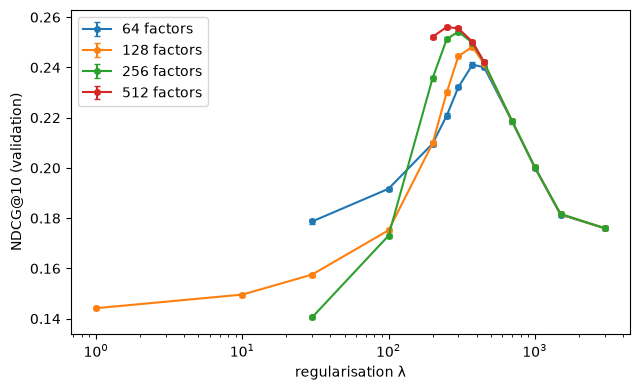

In [7]:
curve = als_grid[(als_grid["weighting"] == "none") & (als_grid["alpha"] == ex.ALS_ALPHA)]
fig, ax = plt.subplots(figsize=(6.5, 4))
for factors, part in curve.groupby("factors"):
    part = part.sort_values("reg")
    ax.errorbar(part["reg"], part["ndcg@10"], yerr=part["ndcg_se"], marker="o", ms=4, capsize=2, label=f"{factors} factors")
ax.set_xscale("log")
ax.set_xlabel("regularisation λ")
ax.set_ylabel("NDCG@10 (validation)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "als_lambda.pdf")
plt.show()

### Chosen settings

The table lists, per method, how many settings were tried, the setting the one-SE rule picked, and its validation NDCG next to the best one.

In [8]:
def describe(row, keys):
    return ", ".join(f"{k}={row[k]:g}" if isinstance(row[k], (int, float, np.integer, np.floating)) else f"{k}={row[k]}" for k in keys)

rule_keys = ["pair_support", "triple_support", "aggregate"]
summary = pd.DataFrame([
    ("Association rules (pairs)", (~rules_grid["uses triples"]).sum(), describe(rules_pairs, rule_keys), rules_pairs["ndcg@10"], rules_grid.loc[~rules_grid["uses triples"], "ndcg@10"].max()),
    ("Association rules (pairs + triples)", rules_grid["uses triples"].sum(), describe(rules_triples, rule_keys), rules_triples["ndcg@10"], rules_grid.loc[rules_grid["uses triples"], "ndcg@10"].max()),
    ("Item-kNN", len(knn_grid), describe(knn_choice, ["measure", "k"]), knn_choice["ndcg@10"], knn_grid["ndcg@10"].max()),
    ("ALS", (als_grid["weighting"] == "none").sum(), describe(als_choice, als_keys), als_choice["ndcg@10"], als_grid.loc[als_grid["weighting"] == "none", "ndcg@10"].max()),
    ("ALS + idf", (als_grid["weighting"] == "idf").sum(), describe(idf_choice, als_keys), idf_choice["ndcg@10"], als_grid.loc[als_grid["weighting"] == "idf", "ndcg@10"].max()),
], columns=["method", "settings tried", "chosen setting", "chosen NDCG@10", "best NDCG@10"])
display(summary.round(4))

,method,settings tried,chosen setting,chosen NDCG@10,best NDCG@10
0,Association rules (pairs),8,"pair_support=120, triple_support=0, aggregate=max",0.2395,0.2399
1,Association rules (pairs + triples),24,"pair_support=120, triple_support=150, aggregat...",0.2385,0.2394
2,Item-kNN,20,"measure=cosine, k=5",0.2295,0.2295
3,ALS,46,"weighting=none, alpha=3, factors=512, reg=300",0.2555,0.2561
4,ALS + idf,9,"weighting=idf, alpha=3, factors=512, reg=250",0.2563,0.2569


## 3. Convergence of ALS

Training loss and validation NDCG after every sweep for the chosen setting of the headline ALS variant, from three random starting points, run to 30 sweeps. The loss is computed sparsely (`als.loss`), without forming the full users × games matrix.

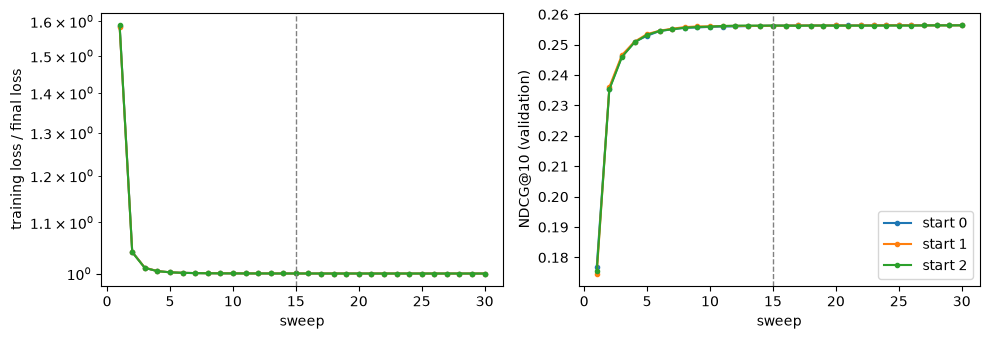

NDCG at sweep 15: [0.2563, 0.2562, 0.2563]; at sweep 30: [0.2564, 0.2564, 0.2564]


In [9]:
slug = "_".join(f"{k}{chosen_als[k]:g}" if k != "weighting" else chosen_als[k] for k in als_keys)
trace = ex.cached_table(f"convergence_{slug}", lambda: pd.concat(
    [ex.convergence_trace(train, valid, chosen_als, seed, CONVERGENCE_SWEEPS) for seed in range(CONVERGENCE_SEEDS)]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for seed, part in trace.groupby("seed"):
    axes[0].plot(part["sweep"], part["loss"] / part["loss"].iloc[-1], marker=".", label=f"start {seed}")
    axes[1].plot(part["sweep"], part["ndcg@10"], marker=".", label=f"start {seed}")
axes[0].set_ylabel("training loss / final loss")
axes[0].set_yscale("log")
axes[1].set_ylabel("NDCG@10 (validation)")
for ax in axes:
    ax.axvline(ex.ITERATIONS, color="grey", ls="--", lw=1)
    ax.set_xlabel("sweep")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "als_convergence.pdf")
plt.show()

at = trace.pivot(index="sweep", columns="seed", values="ndcg@10")
print(f"NDCG at sweep {ex.ITERATIONS}: {at.loc[ex.ITERATIONS].round(4).tolist()}; at sweep {CONVERGENCE_SWEEPS}: {at.loc[CONVERGENCE_SWEEPS].round(4).tolist()}")

## 4. Test results

Each method is refitted on training + validation games with its chosen setting and scored once on the test games. Refitting brings back the validation games, so each basket holds about 1.25× as many games; a support threshold for k-item sets is scaled by that factor to the power k so it keeps its meaning (`itemsets.scale_support`).

The whole comparison is repeated on five random splits (seed 0 is the split used for tuning; the settings stay fixed). Besides accuracy we report:
- **coverage**: share of all games recommended to at least one user;
- **long-tail share**: share of recommended slots filled with games outside the 20% most-played;
- **intra-list similarity**: mean cosine similarity (of the games' player sets) between the games in a list; lower means more varied lists.

In [10]:
def scaled(cfg):
    return {
        "pair_support": itemsets.scale_support(int(cfg["pair_support"]), train, train_full, 2),
        "triple_support": itemsets.scale_support(int(cfg["triple_support"]), train, train_full, 3),
        "aggregate": str(cfg["aggregate"]),
    }

as_als = lambda row: {"weighting": str(row["weighting"]), "alpha": float(row["alpha"]),
                      "factors": int(row["factors"]), "reg": float(row["reg"])}
settings = {
    "rules_pairs": scaled(rules_pairs),
    "rules_triples": scaled(rules_triples),
    "knn": {"measure": str(knn_choice["measure"]), "k": int(knn_choice["k"])},
    "als": as_als(als_choice),
    "als_idf": as_als(idf_choice),
    "headline": best_als,
}
print(f"games per basket grow {train_full.nnz / train.nnz:.3f}x on refit; settings: {settings}")

test_scores, diversity, per_user = ex.test_runs(inter.playtime, list(range(N_SEEDS)), settings, CLUSTER_KS, CAPS)

games per basket grow 1.250x on refit; settings: {'rules_pairs': {'pair_support': 187, 'triple_support': 0, 'aggregate': 'max'}, 'rules_triples': {'pair_support': 187, 'triple_support': 293, 'aggregate': 'max'}, 'knn': {'measure': 'cosine', 'k': 5}, 'als': {'weighting': 'none', 'alpha': 3.0, 'factors': 512, 'reg': 300.0}, 'als_idf': {'weighting': 'idf', 'alpha': 3.0, 'factors': 512, 'reg': 250.0}, 'headline': 'ALS + idf'}


**Split 0** with 95% bootstrap intervals for NDCG (users resampled 1,000 times). Coverage is not bootstrapped: it counts distinct games over all users, and a resample holds only about 63% distinct users, which would bias it downwards; its spread over the five splits is shown further down.

In [11]:
metric_cols = ["precision@10", "recall@10", "ndcg@10", "coverage", "long tail share", "intra-list similarity"]
split0 = test_scores[test_scores["seed"] == 0].set_index("method")[metric_cols]
split0.insert(3, "NDCG 95% interval", [
    "[{:.3f}, {:.3f}]".format(*evaluate.bootstrap_interval(per_user[m])) for m in split0.index])
display(split0.round(3))
split0.round(4).to_csv(FIGURES / "test_results.csv")

,precision@10,recall@10,ndcg@10,NDCG 95% interval,coverage,long tail share,intra-list similarity
method,,,,,,,
Popularity,0.136,0.182,0.223,"[0.221, 0.224]",0.012,0.000,0.376
Rules (pairs),0.197,0.258,0.321,"[0.319, 0.323]",0.071,0.002,0.337
Rules (pairs + triples),0.199,0.261,0.322,"[0.320, 0.324]",0.061,0.000,0.342
Item-kNN,0.195,0.260,0.302,"[0.300, 0.303]",0.509,0.037,0.282
ALS,0.229,0.296,0.357,"[0.356, 0.359]",0.245,0.003,0.262
ALS + idf,0.228,0.292,0.355,"[0.353, 0.357]",0.289,0.007,0.265


**Paired differences** on split 0: both methods are scored on the same users, so the bootstrap resamples the per-user differences. We make four comparisons, so each interval uses the Bonferroni correction (level 1 − 0.05/4), in the spirit of the Bonferroni principle from the course: the more comparisons, the more likely one of them looks real by chance.

In [12]:
course_methods = {"Rules (pairs)": rules_pairs["ndcg@10"], "Rules (pairs + triples)": rules_triples["ndcg@10"],
                  "Item-kNN": knn_choice["ndcg@10"]}
best_course = max(course_methods, key=course_methods.get)  # chosen on validation, not test
comparisons = [(best_als, best_course), ("ALS", "ALS + idf"),
               ("Rules (pairs + triples)", "Rules (pairs)"), (best_course, "Popularity")]
level = 1 - 0.05 / len(comparisons)
display(pd.DataFrame([
    {"comparison": f"{a} − {b}", **evaluate.paired_difference(per_user[a], per_user[b], level=level)}
    for a, b in comparisons
]).round(4))

,comparison,difference,low,high,se
0,ALS + idf − Rules (pairs),0.0342,0.0323,0.0360,0.0008
1,ALS − ALS + idf,0.0020,0.0011,0.0028,0.0003
2,Rules (pairs + triples) − Rules (pairs),0.0007,-0.0000,0.0013,0.0003
3,Rules (pairs) − Popularity,0.0986,0.0969,0.1004,0.0007


**All five splits**: mean ± standard deviation over splits, and whether the order of the methods by NDCG ever changes.

In [13]:
over_splits = test_scores.groupby("method")[["ndcg@10", "coverage", "long tail share", "intra-list similarity"]].agg(["mean", "std"])
display(over_splits.sort_values(("ndcg@10", "mean"), ascending=False).round(4))

orders = test_scores.sort_values(["seed", "ndcg@10"], ascending=[True, False]).groupby("seed")["method"].apply(tuple)
print("same NDCG order on every split:", orders.nunique() == 1)
print(orders.iloc[0])

ndcg@10         coverage         long tail share  \
                           mean     std     mean     std            mean   
method                                                                     
ALS                      0.3562  0.0013   0.2453  0.0009          0.0033   
ALS + idf                0.3545  0.0012   0.2906  0.0026          0.0070   
Rules (pairs + triples)  0.3218  0.0009   0.0606  0.0005          0.0005   
Rules (pairs)            0.3213  0.0006   0.0699  0.0008          0.0013   
Item-kNN                 0.3018  0.0008   0.5087  0.0035          0.0376   
Popularity               0.2219  0.0008   0.0128  0.0006          0.0000   

                                intra-list similarity          
                            std                  mean     std  
method                                                         
ALS                      0.0001                0.2623  0.0001  
ALS + idf                0.0001                0.2654  0.0002  
Rules (pairs + triples)  0.0001                0.3431  0.0004  
Rules (pairs)            0.0003                0.3374  0.0004  
Item-kNN                 0.0004                0.2825  0.0006  
Popularity               0.0000                0.3761  0.0003

same NDCG order on every split: True
('ALS', 'ALS + idf', 'Rules (pairs + triples)', 'Rules (pairs)', 'Item-kNN', 'Popularity')


## 5. Cross-check against the `implicit` library

`implicit` implements the same paper. It reads every stored value as the confidence itself (c = α · value), so we give it our confidence matrix with α = 1, start it from our exact initial vectors, and use its exact (Cholesky) solver. If both implementations are right, the two models must give the same scores. (The unit test `tests/test_als.py` checks a single least-squares solve against `implicit` to 1e-12; here we check whole fits, at `CHECK_FACTORS` = 128 factors to keep `implicit`'s run short.)

In [14]:
from implicit.cpu.als import AlternatingLeastSquares

check = {**chosen_als, "weighting": "none", "factors": CHECK_FACTORS}
conf = als.confidence(train_full, check["alpha"])
ours = als.fit(conf, check["factors"], check["reg"], ex.ITERATIONS, seed=0)

lib = AlternatingLeastSquares(factors=check["factors"], regularization=check["reg"], alpha=1.0,
                              iterations=ex.ITERATIONS, use_cg=False, dtype=np.float64, random_state=0)
lib.user_factors, lib.item_factors = (v.copy() for v in als.initial_factors(conf.shape, check["factors"], seed=0))
lib.fit(conf, show_progress=False)
theirs = als.ALSModel(np.asarray(lib.user_factors), np.asarray(lib.item_factors))

sample = np.arange(5000)
gap = np.abs(ours.user_factors[sample] @ ours.item_factors.T - theirs.user_factors[sample] @ theirs.item_factors.T).max()
same_lists = (evaluate.top_k(evaluate.als_scorer(ours), train_full) ==
              evaluate.top_k(evaluate.als_scorer(theirs), train_full)).all(axis=1).mean()
print(f"largest score difference (first 5,000 users): {gap:.1e}; identical top-10 lists: {same_lists:.2%} of users")

largest score difference (first 5,000 users): 1.7e-08; identical top-10 lists: 100.00% of users


## 6. What ALS learned

The headline ALS model, refitted on split 0's training + validation games.

In [15]:
final = ex.fit_als(train_full, **settings["als" if best_als == "ALS" else "als_idf"], seed=0)  # headline variant
name_to_index = {inter.item_names[g]: i for i, g in enumerate(inter.item_ids)}
title = lambda i: inter.item_names[inter.item_ids[i]]

similar = {}
for game in ["Counter-Strike: Global Offensive", "Euro Truck Simulator 2", "Dark Souls: Prepare to Die Edition"]:
    top, _ = als.similar_items(final, name_to_index[game], 6)
    similar[game] = [title(i) for i in top]
display(pd.DataFrame(similar))

,Counter-Strike: Global Offensive,Euro Truck Simulator 2,Dark Souls: Prepare to Die Edition
0,Garry's Mod,Bus Driver,DARK SOULS™ II
1,Left 4 Dead 2,American Truck Simulator,DARK SOULS™ II: Scholar of the First Sin
2,Unturned,Scania Truck Driving Simulator,DARK SOULS III
3,PAYDAY 2,OMSI 2,The Witcher 2: Assassins of Kings Enhanced Edi...
4,Counter-Strike: Source,Spintires,The Witcher: Enhanced Edition
5,Terraria,Bus-Simulator 2012,Dragon's Dogma: Dark Arisen


### Clusters of game vectors

ALS scores a user–game pair by a dot product, so a game's taste profile is the **direction** of its vector; the length mostly reflects how much data the game has (the correlation below). We therefore cluster directions with **spherical k-means** (`clusters.spherical_kmeans`): every vector is scaled to length 1, games are assigned to the centroid with the highest cosine similarity, and centroids are scaled back to length 1 after each update. Plain k-means on unit vectors only approximates this, because its centroids are shorter than 1. DBSCAN is not used because it leaves noise points without a cluster, and the diversification below needs every game to have one.

For each k: Davies–Bouldin index (lower is better), adjusted mutual information (AMI) between clusters and each game's most-voted *content* tag (meta tags such as Indie or Early Access skipped; AMI is 0 for random labels at any k), the AMI of shuffled clusters, the agreement between runs from different random starts (adjusted Rand index, 1 = identical), and the share of all ALS top-10 slots that fall in the single most-recommended cluster.

In [16]:
players_full = data.players_per_game(train_full)
lengths = np.linalg.norm(final.item_factors, axis=1)
print(f"Spearman correlation between vector length and number of players: {spearmanr(lengths, players_full).statistic:.2f}")

game_tags = clusters.load_game_tags()
tagged = np.array([g in game_tags for g in inter.item_ids])
tag_lists = [game_tags[g] for g in inter.item_ids[tagged]]
print(f"{tagged.sum():,} of {n_games:,} games have a record with tags in steam_games.json.gz")

final_recs = evaluate.top_k(evaluate.als_scorer(final), train_full)
sweep, labels_by_k = clusters.kmeans_sweep(final.item_factors, [5, 10, 20, 40, 80])
extra = []
for k in sweep["k"]:
    ami, shuffled = clusters.ami_with_top_tag(labels_by_k[k][tagged], tag_lists)
    extra.append({
        "AMI": ami, "AMI shuffled": shuffled,
        "seed agreement (ARI)": clusters.seed_agreement(final.item_factors, k, [0, 1, 2]),
        "largest cluster share of top-10": clusters.largest_cluster_share(final_recs, labels_by_k[k]),
    })
sweep = pd.concat([sweep, pd.DataFrame(extra)], axis=1)
display(sweep.round(3))

Spearman correlation between vector length and number of players: 0.91


3,206 of 3,718 games have a record with tags in steam_games.json.gz


,k,davies_bouldin,AMI,AMI shuffled,seed agreement (ARI),largest cluster share of top-10
0,5,3.031,0.155,0.000,0.982,0.631
1,10,2.694,0.193,0.000,0.942,0.752
2,20,2.641,0.217,0.000,0.702,0.673
3,40,2.500,0.241,-0.001,0.595,0.497
4,80,2.325,0.255,-0.001,0.550,0.294


The 12 largest clusters at the k with the lowest Davies–Bouldin index, each described by tags that are both common in it (on at least 20% of its games) and over-represented compared with all games.

In [17]:
describe_k = int(sweep.loc[sweep["davies_bouldin"].idxmin(), "k"])
with pd.option_context("display.max_colwidth", None):
    display(clusters.tag_profile(labels_by_k[describe_k][tagged], tag_lists).head(12))

,cluster,games,tags (share in cluster vs overall)
0,0,183,"Female Protagonist (20% vs 12%), Puzzle (28% vs 17%), Casual (36% vs 27%), 2D (28% vs 22%)"
1,52,142,"Female Protagonist (24% vs 12%), Puzzle (29% vs 17%), Platformer (21% vs 13%), 2D (35% vs 22%)"
2,56,131,"Puzzle (27% vs 17%), Casual (35% vs 27%), 2D (28% vs 22%), Adventure (49% vs 51%)"
3,71,122,"Platformer (20% vs 13%), Casual (43% vs 27%), Adventure (46% vs 51%), Action (54% vs 63%)"
4,10,87,"Difficult (51% vs 15%), Platformer (37% vs 13%), Puzzle (41% vs 17%), 2D (44% vs 22%)"
5,40,85,"Casual (33% vs 27%), Shooter (22% vs 20%), Action (67% vs 63%), 2D (22% vs 22%)"
6,20,84,"RPGMaker (23% vs 2%), Shoot 'Em Up (35% vs 4%), Anime (36% vs 9%), Family Friendly (21% vs 6%)"
7,62,74,"Puzzle (59% vs 17%), Casual (58% vs 27%), Platformer (27% vs 13%), 2D (43% vs 22%)"
8,11,68,"Turn-Based (26% vs 8%), Space (22% vs 7%), Fantasy (38% vs 16%), Strategy (71% vs 31%)"
9,79,64,"Rogue-lite (33% vs 2%), Procedural Generation (25% vs 2%), Rogue-like (38% vs 4%), Pixel Graphics (55% vs 11%)"


## 7. Diversifying the lists by cluster

`diversify.capped_top_k` walks each user's full ALS ranking and takes the best game whose cluster still has room, at most `cap` games per cluster (if the caps cannot fill ten slots, the best skipped games fill the rest). The clusters come from each split's refitted model, which never saw that split's test games. No setting is chosen from these results: the trade-off curve itself is the result, since NDCG on the hidden games always prefers no cap (the hidden games are themselves mostly popular hits). Mean over the five splits, with the standard deviation as error bars.

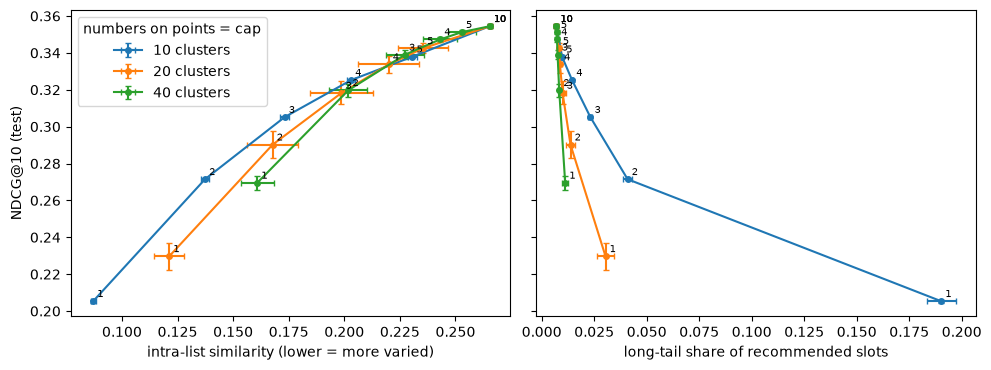

ndcg@10  intra-list similarity  long tail share  coverage  \
clusters cap                                                              
10       1      0.205                  0.087            0.190     0.344   
         2      0.271                  0.137            0.041     0.309   
         3      0.305                  0.173            0.023     0.305   
         4      0.325                  0.203            0.014     0.305   
         5      0.338                  0.231            0.010     0.299   
         10     0.354                  0.265            0.007     0.291   
20       1      0.230                  0.121            0.030     0.310   
         2      0.290                  0.168            0.014     0.306   
         3      0.318                  0.199            0.010     0.302   
         4      0.334                  0.220            0.009     0.297   
         5      0.342                  0.235            0.008     0.294   
         10     0.354                  0.265            0.007     0.291   
40       1      0.270                  0.161            0.011     0.305   
         2      0.320                  0.202            0.008     0.300   
         3      0.339                  0.227            0.008     0.296   
         4      0.347                  0.243            0.007     0.293   
         5      0.351                  0.253            0.007     0.290   
         10     0.354                  0.265            0.007     0.291   

              largest cluster share  
clusters cap                         
10       1                    0.100  
         2                    0.200  
         3                    0.300  
         4                    0.398  
         5                    0.493  
         10                   0.748  
20       1                    0.100  
         2                    0.199  
         3                    0.294  
         4                    0.383  
         5                    0.462  
         10                   0.676  
40       1                    0.100  
         2                    0.197  
         3                    0.286  
         4                    0.358  
         5                    0.412  
         10                   0.499

In [18]:
curve = diversity.groupby(["clusters", "cap"]).agg(["mean", "std"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for k, part in curve.groupby(level="clusters"):
    for ax, x in zip(axes, ["intra-list similarity", "long tail share"]):
        ax.errorbar(part[(x, "mean")], part[("ndcg@10", "mean")], xerr=part[(x, "std")], yerr=part[("ndcg@10", "std")],
                    marker="o", ms=4, capsize=2, label=f"{k} clusters")
        for cap_value, row in part.iterrows():
            ax.annotate(str(cap_value[1]), (row[(x, "mean")], row[("ndcg@10", "mean")]), fontsize=7,
                        xytext=(3, 3), textcoords="offset points")
axes[0].set_xlabel("intra-list similarity (lower = more varied)")
axes[1].set_xlabel("long-tail share of recommended slots")
axes[0].set_ylabel("NDCG@10 (test)")
axes[0].legend(title="numbers on points = cap")
fig.tight_layout()
fig.savefig(FIGURES / "diversity_tradeoff.pdf")
plt.show()

display(curve.xs("mean", axis=1, level=1)[["ndcg@10", "intra-list similarity", "long tail share", "coverage", "largest cluster share"]].round(3))

## Notes for the report

(Filled in after the run.)